In [3]:
#Write your starter code below
import pandas as pd

#Load the raw data 
df = pd.read_csv("data/log2.csv")

# Part 1 Prepare the  data
"""
Edgar
"""


#Question 1. Report the original number of records and list the distinct Action values.

#Prints the number of records of network traffic according to dataset
print(len(df))

#Prints a list of unique "Action values" by first selecting the column "Action" the dataset
print(df["Action"].unique())

65532
['allow' 'drop' 'deny' 'reset-both']


In [4]:
df.head()

,Source Port,Destination Port,NAT Source Port,NAT Destination Port,Action,Bytes,Bytes Sent,Bytes Received,Packets,Elapsed Time (sec),pkts_sent,pkts_received
0,57222,53,54587,53,allow,177,94,83,2,30,1,1
1,56258,3389,56258,3389,allow,4768,1600,3168,19,17,10,9
2,6881,50321,43265,50321,allow,238,118,120,2,1199,1,1
3,50553,3389,50553,3389,allow,3327,1438,1889,15,17,8,7
4,50002,443,45848,443,allow,25358,6778,18580,31,16,13,18


In [5]:
df['Destination Port'].value_counts()

Destination Port
53       15414
445      12891
443      11684
80        4035
25174     1087
         ...  
20009        1
48608        1
10016        1
13384        1
22455        1
Name: count, Length: 3273, dtype: int64

In [6]:
#  Firewall outcome
df['Action'].value_counts()

Action
allow         37640
deny          14987
drop          12851
reset-both       54
Name: count, dtype: int64

In [7]:
# Question 2. Check the two required columns for missing or invalid values. Exclude affected records and report how many
# were excluded.

#Prints the number of actions that are missing within the dataset
print(df["Action"].isna().sum())

#Prints the number of destination ports that are missing within the dataset
print(df["Destination Port"].isna().sum())

0
0


In [8]:

#Checks and prints the dataset Destination Port values to 
#gauge possible invalid values (anything outside of network port range 0-65535)
print(df["Destination Port"].min())
print(df["Destination Port"].max())


0
65535


In [9]:
#Prints number of values that are invalid/outside our range, all based from values in Destination Port column
print((~df["Destination Port"].between(0,65535)).sum())

#Prints the number of values that are not whole numbers, meaning they're invalid values 
print((df["Destination Port"] % 1 !=0).sum())

0
0


In [10]:
#Prints the number of values in the Action column that are not the 4 acceptable action values
print((~df["Action"].isin(["allow", "drop", "deny", "reset-both"])).sum())

#Transfers the cleaned/checked dataset to a copy that group members will use
df_cleaned = df.copy()

0


In [11]:
# No records excluded after checking, so excluded is simply 0
excluded_records = 0
print("Number of excluded records is: ", excluded_records)

#Prints the final number of usable records, N, which is confirmed to be all original records
N = len(df_cleaned)
print("Final number of usable records, N, is: ", N)

Number of excluded records is:  0
Final number of usable records, N, is:  65532


In [12]:
#Defining and implementing "Destination port" and "Firewall outcome" as two categories in dataset
def categorize_port(port):
    if port == 53:
        return "Port 53"
    elif port == 80:
        return "Port 80"
    elif port == 443:
        return "Port 443"
    else:
        return "Other"    


In [13]:
#Creates a new column in dataset and prints the number of each category of Destination Port
df_cleaned["X"] = df_cleaned["Destination Port"].apply(categorize_port)
print(df_cleaned["X"].value_counts())

X
Other       34399
Port 53     15414
Port 443    11684
Port 80      4035
Name: count, dtype: int64


In [14]:
#
def categorize_action(action):
    if action == "allow":
        return "Allowed"
    else:
        return "Not Allowed" 

In [15]:
#Creates a new column in dataset and prints the number of each category of Action
df_cleaned["Y"] = df_cleaned["Action"].apply(categorize_action)
print(df_cleaned["Y"].value_counts())

Y
Allowed        37640
Not Allowed    27892
Name: count, dtype: int64


# Part 2

In [16]:

import pandas as pd

# Create destination-port categories
df_cleaned["Port_Category"] = df_cleaned["Destination Port"].apply(
    lambda port: (
        "Port 53" if port == 53 else
        "Port 80" if port == 80 else
        "Port 443" if port == 443 else
        "Other"
    )
)

# Create firewall outcome categories
df_cleaned["Outcome"] = df_cleaned["Action"].apply(
    lambda action: "Allowed" if action == "allow"
    else "Not allowed"
)

# Construct the frequency table
frequency_table = pd.crosstab(
    df_cleaned["Port_Category"],
    df_cleaned["Outcome"],
    margins=True,
    margins_name="Total"
)

# Display rows and columns in the assignment's order
frequency_table = frequency_table.reindex(
    ["Port 53", "Port 80", "Port 443", "Other", "Total"],
    axis=0
)

frequency_table = frequency_table.reindex(
    ["Allowed", "Not allowed", "Total"],
    axis=1
)

print(frequency_table)


Outcome        Allowed  Not allowed  Total
Port_Category                             
Port 53          15385           29  15414
Port 80           4028            7   4035
Port 443         11677            7  11684
Other             6550        27849  34399
Total            37640        27892  65532


In [17]:
frequency_table.loc["Port 53",'Allowed']

15385

B. Construct the joint probability table by dividing each interior cell count by N. 𝑃̂
(𝑋 = 𝑥, 𝑌 = 𝑦) = 𝑛ₓᵧ/𝑁

In [18]:
N = df_cleaned['Y'].value_counts().sum()
port_list = ["Port 53", "Port 80", "Port 443", "Other"]

P_XY = []
for port in port_list:
    for action in ["Allowed", "Not allowed"]:
        p = frequency_table.loc[port,action]
        P_XY.append((p/N))

print(N)
print(P_XY)
print("Joint Probability: " ,sum(P_XY))

65532
[0.23477079899896233, 0.0004425318928157236, 0.06146615394005982, 0.00010681804309345053, 0.1781877556003174, 0.00010681804309345053, 0.09995116889458586, 0.424967954587072]
Joint Probability:  1.0


In [19]:
df_cleaned.head()

,Source Port,Destination Port,NAT Source Port,NAT Destination Port,Action,Bytes,Bytes Sent,Bytes Received,Packets,Elapsed Time (sec),pkts_sent,pkts_received,X,Y,Port_Category,Outcome
0,57222,53,54587,53,allow,177,94,83,2,30,1,1,Port 53,Allowed,Port 53,Allowed
1,56258,3389,56258,3389,allow,4768,1600,3168,19,17,10,9,Other,Allowed,Other,Allowed
2,6881,50321,43265,50321,allow,238,118,120,2,1199,1,1,Other,Allowed,Other,Allowed
3,50553,3389,50553,3389,allow,3327,1438,1889,15,17,8,7,Other,Allowed,Other,Allowed
4,50002,443,45848,443,allow,25358,6778,18580,31,16,13,18,Port 443,Allowed,Port 443,Allowed


#### 3 Find the probability that a record uses port 53 and is not allowed. (What percentage of all records use port 53 and are not allowed?

In [20]:
print("P ( Port 53 and Not Allowed ): ", frequency_table.loc["Port 53", "Not allowed"] / N)

P ( Port 53 and Not Allowed ):  0.0004425318928157236


#### 4 Find the probability that a record uses either port 80 or port 443, and is allowed. (What percentage of all records use either port 80 or port 443 and are allowed?)

In [21]:
print("P (Port 80 or Port 443 and Allowed) : ", (frequency_table.loc['Port 80', 'Allowed'] + frequency_table.loc['Port 443', 'Allowed'])/N)
print("Percentage of (Port 80 or Port 443 and Allowed) : ",( (frequency_table.loc['Port 80', 'Allowed'] + frequency_table.loc['Port 443', 'Allowed'])/N)*100)

P (Port 80 or Port 443 and Allowed) :  0.2396539095403772
Percentage of (Port 80 or Port 443 and Allowed) :  23.965390954037723


# Part 3: OM

Part 3 Marginal distributions 10 points
Calculate both marginal distributions by summing the joint probabilities. 𝑃̂
(𝑋 = 𝑥) = ∑𝑃̂ (𝑋 = 𝑥, 𝑌 = 𝑦)
𝑦 𝑃̂
(𝑌 = 𝑦) = ∑𝑃̂ (𝑋 = 𝑥, 𝑌 = 𝑦)
𝑥
1. Present a marginal probability table for each variable and verify that each distribution sums to 1.
2. Identify the most common destination-port category.
3. Report the overall probability that a record is allowed.
4. Explain what information is lost when examining only the marginal distribution

In [22]:

# Remove the Total row and Total column
counts = frequency_table.loc[
    ["Port 53", "Port 80", "Port 443", "Other"],
    ["Allowed", "Not allowed"]
]

# Total number of usable records
N = counts.to_numpy().sum()

# Joint probability table
joint_probability = counts / N


print("Joint Probability Table:")
print(joint_probability.round(4))




Joint Probability Table:
Outcome        Allowed  Not allowed
Port_Category                      
Port 53         0.2348       0.0004
Port 80         0.0615       0.0001
Port 443        0.1782       0.0001
Other           0.1000       0.4250


In [23]:
# Marginal Probability For X
port_list = ["Port 53", "Port 80", "Port 443", "Other"]
X_list = []
for port in port_list:
    val = frequency_table.loc[port,"Allowed"] + frequency_table.loc[port ,"Not allowed" ]
    X_list.append(val/N)


print("Marginal distribution of Port \"X\" Category :\n ", port_list)
print( X_list)


Marginal distribution of Port "X" Category :
  ['Port 53', 'Port 80', 'Port 443', 'Other']
[0.23521333089177807, 0.06157297198315327, 0.17829457364341086, 0.5249191234816578]


In [24]:
# Marginal Probability For Y
Y_list = []
Y_total_value = 0
for action in ["Allowed" , "Not allowed"]:
    val = 0
    for port in port_list:
        val += frequency_table.loc[port, action]

    Y_list.append(val/N)
    Y_total_value = val
print("Marginal distribution of Y (Outcome)\n",["Allowed","Not allowed"])
print("\n",Y_list)



Marginal distribution of Y (Outcome)
 ['Allowed', 'Not allowed']

 [0.5743758774339254, 0.42562412256607457]


In [25]:
 # Verify that each distribution sums to 1
print("Sum of marginal probability of X: " , sum(X_list))
print("Sum of marginal probability of Y: " , sum(Y_list))

Sum of marginal probability of X:  1.0
Sum of marginal probability of Y:  1.0


##### Q2. Identify the most common destination-port category.
--> The most common destination-port category is other with probability of  0.52. After that, most common category is Port 53 with probability of 0.235.

#### Q3. Report the overall probability that a record is allowed

In [26]:
print("Overall probability a record is allowed : ", Y_total_value / N)

Overall probability a record is allowed :  0.42562412256607457


#### 4. Explain what information is lost when examining only the marginal distributions.

--> Marginal distributions show the overall probabilities of destination-port categories and firewall outcomes separately. However, they do not show how firewall outcomes vary across different destination-port categories. For example, the marginal distribution tells us the overall proportion of allowed records but does not tell us whether records using Port 53, Port 80, or Port 443 are more likely to be allowed. To understand the relationship between destination port and firewall outcome, we need the joint or conditional distributions.

# Part 4 Conditional distributions 20 points
Calculate the following probabilities. For each, show the numerator and denominator, report the probability,
and interpret it in context. 𝑃̂
(𝑌 = 𝐴𝑙𝑙𝑜𝑤𝑒𝑑 | 𝑋 = 𝑃𝑜𝑟𝑡 443), 𝑃̂ (𝑋 = 𝑃𝑜𝑟𝑡 443|𝑌 = 𝐴𝑙𝑙𝑜𝑤𝑒𝑑 ) 𝑃̂
(𝑌 = 𝑁𝑜𝑡 𝑎𝑙𝑙𝑜𝑤𝑒𝑑 | 𝑋 = 𝑃𝑜𝑟𝑡 53),𝑃̂ ( 𝑋 = 𝑃𝑜𝑟𝑡 53 | 𝑌 = 𝑁𝑜𝑡 𝑎𝑙𝑙𝑜𝑤𝑒𝑑)
If the conditioning category has no records, report the probability as undefined and explain why.
1. Construct the conditional distribution of firewall outcome within each destination-port category. Verify that each nonempty row sums to 1.
2. Create a bar chart comparing the probability of being allowed across the four port categories. Provide the
underlying values in a table.
3. Explain why P(Allowed | Port 443) and P(Port 443 | Allowed) answer different questions

#### What is a conditional probability?
A conditional probability asks: What is the probability of an event when we already know another event has happened?

In [27]:
# P(Y = Allowed | X  = Port 443)

print("P(Y = Allowed | X  = Port 443 ): ", frequency_table.loc["Port 443","Allowed"] / frequency_table.loc["Port 443",'Total'])
print("P(X = Port 443 | Y = Allowed )  ", frequency_table.loc["Port 443","Allowed"] / frequency_table.loc["Total",'Allowed'])
print("P(Y = Not allowed | X = Port 53 ) :  ", frequency_table.loc["Port 53","Not allowed"] / frequency_table.loc["Port 53","Total"])
print("P(X = Port 53 | Y = Not allowed ) :  ", frequency_table.loc["Port 53","Not allowed"] / frequency_table.loc["Total", "Not allowed"])

P(Y = Allowed | X  = Port 443 ):  0.9994008901061281
P(X = Port 443 | Y = Allowed )   0.3102284803400638
P(Y = Not allowed | X = Port 53 ) :   0.0018814065135591021
P(X = Port 53 | Y = Not allowed ) :   0.00103972465223003


1. Construct the conditional distribution of firewall outcome within each destination-port category. Verify that each nonempty row sums to 1.

In [28]:
# Use the frequency table from Part 2A
counts = frequency_table.loc[
    ["Port 53", "Port 80", "Port 443", "Other"],
    ["Allowed", "Not allowed"]
]

counts

# Conditional distribution of firewall outcome within each port
conditional_table = counts.div(counts.sum(axis=1), axis=0)

print("\nConditional distribution:")
print(conditional_table.round(4))

print("\nRow sums:")
print(conditional_table.sum(axis=1).round(4))


Conditional distribution:
Outcome        Allowed  Not allowed
Port_Category                      
Port 53         0.9981       0.0019
Port 80         0.9983       0.0017
Port 443        0.9994       0.0006
Other           0.1904       0.8096

Row sums:
Port_Category
Port 53     1.0
Port 80     1.0
Port 443    1.0
Other       1.0
dtype: float64


2. Create a bar chart comparing the probability of being allowed across the four port categories. Provide the
underlying values in a table.

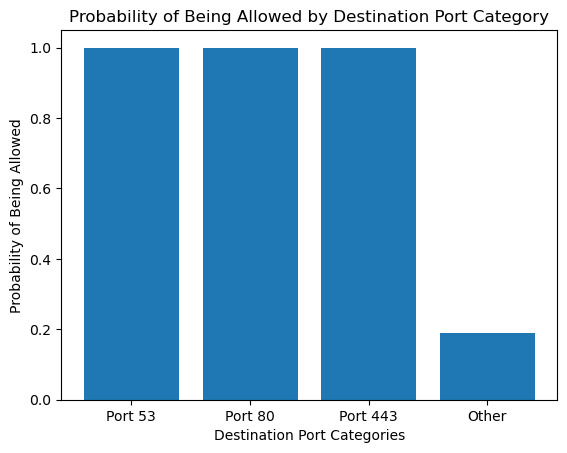

In [29]:
import matplotlib.pyplot as plt


plt.bar( port_list ,conditional_table["Allowed"])
plt.xlabel("Destination Port Categories")
plt.ylabel("Probability of Being Allowed")
plt.title("Probability of Being Allowed by Destination Port Category")
plt.show()

3. Explain why P(Allowed | Port 443) and P(Port 443 | Allowed) answer different questions.
<pre>
--> P(Allowed | Port 443) provides the probability of Port 443 and firewall outcome Allowed given all the sum of all the Port 443 destination category.

Meanwhile, P(Port 443 | Allowed) provides the probability of Port 443 and Allowed out of all the Allowed firewall outcome.

Although, the numerator is same for both the denominator is defferent.

P(Allowed | Port 443)  = n(Allowed | Port 443)/ n(Port 443)

P(Port 443 | Allowed)  = n(Port 443 | Allowed )/ n(Allowed)
</pre>